In [10]:
import os
import sys
import torch
import h5py
import types
from termcolor import colored
from torchmetrics.image import PeakSignalNoiseRatio, StructuralSimilarityIndexMeasure
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt
import numpy as np
import nibabel as nib
import pickle
from sklearn.model_selection import train_test_split
from tqdm import tqdm

import torch.nn as nn
from torchmetrics.image.lpip import LearnedPerceptualImagePatchSimilarity as LPIPS


from torch.utils.data import DataLoader

from torch.utils.data import DataLoader
from torchmetrics.image.ssim import StructuralSimilarityIndexMeasure
from torchmetrics.image.psnr import PeakSignalNoiseRatio
from torchmetrics.regression import MeanSquaredError

from scipy import stats as st
from pathlib import Path



# Update the project root and add to path
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

# Constants

In [ ]:
RANDOM_SEED = 56 # from config
#TEST_SPLIT_RATIO = 0.2

DOMAIN_A_KEY = 'Axial_FLAIR'
DOMAIN_B_KEY = 'Axial_T2'
domain_key_prefixes = [DOMAIN_A_KEY, DOMAIN_B_KEY]

# Paths

In [13]:
MODEL_PATH = "/mnt/ISNLGroup/Mike_Workspace/Experiments/CVPR/model_checkpoints/"

EXP_1_METRICS = "/mnt/ISNLGroup/Mike_Workspace/Experiments/CVPR/metrics/exp_1_stats.pkl"

In [11]:
from models.vqvae2_crossover import Quantize, Encoder, Decoder, VQVAE2_Crossover
from dataloaders.datasets import HDF5MultiDomainDataset
from losses.custom_losses import CustomAggregateLoss 

In [14]:
CHECKPOINT_PATH = "/mnt/ISNLGroup/Mike_Workspace/Experiments/CVPR/model_checkpoints/t2_and_flair.ckpt"

# Model

In [15]:
# This is a way to make this as flexible as possible and minimize code changes that could lead to insideous errors

# We're gonna mimic loading a Hydra config file without actually loading it
cfg = types.SimpleNamespace()
cfg.model = types.SimpleNamespace()

cfg.model.top_codebook_embedding_dim = 128
cfg.model.top_codebook_num_embeddings = 1024
cfg.model.bottom_codebook_embedding_dim = 128
cfg.model.bottom_codebook_num_embeddings = 1024
cfg.model.base_channels = 128
cfg.model.decay_rate = 0.99
cfg.model.input_channels = 3
cfg.model.num_res_blocks = 2
cfg.model.num_res_channels = 32

In [16]:
############################################################################
# Instantiate the Model
############################################################################

# ---------------------------------------------------------------------------
# VQVAE2 Crossover Model (Dual Domain with Crossover)

# --- 1. Instantiate the SHARED Codebooks ---
# These are instantiated ONLY ONCE.
# They will be passed as objects to both model_A and model_B.
shared_quantize_t = Quantize(dim=cfg.model.top_codebook_embedding_dim,
                             n_embed=cfg.model.top_codebook_num_embeddings,
                             decay=cfg.model.decay_rate)

shared_quantize_b = Quantize(dim=cfg.model.bottom_codebook_embedding_dim,
                             n_embed=cfg.model.bottom_codebook_num_embeddings,
                             decay=cfg.model.decay_rate)

# --- 2. Instantiate Encoders and Decoders for Domain A ---
# These are specific to Domain A
enc_b_A = Encoder(in_channel=cfg.model.input_channels,
                  channel=cfg.model.base_channels,
                  n_res_block=cfg.model.num_res_blocks,
                  n_res_channel=cfg.model.num_res_channels,
                  stride=4)

enc_t_A = Encoder(in_channel=cfg.model.base_channels,
                  channel=cfg.model.base_channels,
                  n_res_block=cfg.model.num_res_blocks,
                  n_res_channel=cfg.model.num_res_channels,
                  stride=2)

dec_t_A = Decoder(in_channel=cfg.model.top_codebook_embedding_dim,
                  out_channel=cfg.model.top_codebook_embedding_dim,
                  channel=cfg.model.base_channels,
                  n_res_block=cfg.model.num_res_blocks,
                  n_res_channel=cfg.model.num_res_channels,
                  stride=2)

dec_A = Decoder(in_channel=cfg.model.top_codebook_embedding_dim + cfg.model.bottom_codebook_embedding_dim,
                out_channel=cfg.model.input_channels,
                channel=cfg.model.base_channels,
                n_res_block=cfg.model.num_res_blocks,
                n_res_channel=cfg.model.num_res_channels,
                stride=4)

# --- 3. Instantiate Encoders and Decoders for Domain B ---
# These are specific to Domain B's
enc_b_B = Encoder(in_channel=cfg.model.input_channels,
                  channel=cfg.model.base_channels,
                  n_res_block=cfg.model.num_res_blocks,
                  n_res_channel=cfg.model.num_res_channels,
                  stride=4)

enc_t_B = Encoder(in_channel=cfg.model.base_channels,
                  channel=cfg.model.base_channels,
                  n_res_block=cfg.model.num_res_blocks,
                  n_res_channel=cfg.model.num_res_channels,
                  stride=2)

dec_t_B = Decoder(in_channel=cfg.model.top_codebook_embedding_dim,
                  out_channel=cfg.model.top_codebook_embedding_dim,
                  channel=cfg.model.base_channels,
                  n_res_block=cfg.model.num_res_blocks,
                  n_res_channel=cfg.model.num_res_channels,
                  stride=2)

dec_B = Decoder(in_channel=cfg.model.top_codebook_embedding_dim + cfg.model.bottom_codebook_embedding_dim,
                out_channel=cfg.model.input_channels,
                channel=cfg.model.base_channels,
                n_res_block=cfg.model.num_res_blocks,
                n_res_channel=cfg.model.num_res_channels,
                stride=4)

# --- 4. Instantiate the TWO VQVAE2_Crossover models, passing all required parameters ---
# Model for Domain A
model_A = VQVAE2_Crossover(
    enc_t=enc_t_A,
    enc_b=enc_b_A,
    dec_t=dec_t_A,
    dec=dec_A,
    quantize_t=shared_quantize_t,  # SHARED codebook
    quantize_b=shared_quantize_b,  # SHARED codebook
    in_channel=cfg.model.input_channels,  # Pass this as per your __init__
    channel=cfg.model.base_channels,  # Pass this as per your __init__
    n_res_block=cfg.model.num_res_blocks,  # Pass this as per your __init__
    n_res_channel=cfg.model.num_res_channels,  # Pass this as per your __init__
    decay=cfg.model.decay_rate  # Pass this as per your __init__
)

# Model for Domain B
model_B = VQVAE2_Crossover(
    enc_t=enc_t_B,
    enc_b=enc_b_B,
    dec_t=dec_t_B,
    dec=dec_B,
    quantize_t=shared_quantize_t,  # SHARED codebook (same object as model_A uses)
    quantize_b=shared_quantize_b,  # SHARED codebook (same object as model_A uses)
    in_channel=cfg.model.input_channels,  # Pass this (same for both domains) as per your __init__
    channel=cfg.model.base_channels,  # Pass this as per your __init__
    n_res_block=cfg.model.num_res_blocks,  # Pass this as per your __init__
    n_res_channel=cfg.model.num_res_channels,  # Pass this as per your __init__
    decay=cfg.model.decay_rate  # Pass this as per your __init__
)

domain_models = {
    DOMAIN_A_KEY: model_A,
    DOMAIN_B_KEY: model_B
}

## Loss Functions

In [17]:
recon_loss_fn = CustomAggregateLoss(
    losses={
        "l1": nn.L1Loss(),
        "lpips": LPIPS(net_type="vgg", normalize=True),
    },
    weights={"l1": 1.0, "lpips": 0.80},
)

crossover_loss_fn = CustomAggregateLoss(
    losses={
        "l1": nn.L1Loss(),
        "lpips": LPIPS(net_type="vgg", normalize=True),
    },
    weights={"l1": 1.0, "lpips": 0.80},
)

/opt/anaconda3/envs/clasp_pytorch/lib/python3.10/site-packages/torchmetrics/functional/image/lpips.py:332: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict

In [18]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

try:
    lit_model = LitVQVAE2DualDomainCrossover.load_from_checkpoint(
        CHECKPOINT_PATH,
        domain_models=domain_models, # TEMPORARY! This is only needed for older checkpoints that didn't save domain_models
        recon_loss_fn = recon_loss_fn,
        crossover_loss_fn = crossover_loss_fn
    )
    print("Model loaded successfully from checkpoint.")
except Exception as e:
    print(colored(f"Failed to load model from checkpoint: {e}", 'red'))

Using device: cuda
Model loaded successfully from checkpoint.


## Prepare Model for Eval

In [19]:
# Set the model to evaluation mode and move to device
lit_model.eval()
lit_model.freeze() 
lit_model.to(device)

# Access the individual domain models
flair_model = lit_model.domain_models[DOMAIN_A_KEY] # Specific names for now
t2_model = lit_model.domain_models[DOMAIN_B_KEY]

# Experiment 2

## Prepare the Data

In [24]:
BRATS_PATH = "/mnt/ISNLGroup/Mike_Workspace/Data/RSNA-ASNR-MICCAI-BraTS-2021/BRaTS_2021_Processed/"
h5_files = sorted(Path(BRATS_PATH).glob("*.h5"))
print(f"Found {len(h5_files[:400])} .h5 files")

test_dataset = HDF5MultiDomainDataset(
    h5_file_list=h5_files[:400],
    domain_key_prefixes=domain_key_prefixes,
    transform=None,   # no augmentation for eval
)

loader = DataLoader(test_dataset, 
                    batch_size=32, 
                    shuffle=False, 
                    num_workers=12, 
                    pin_memory=True)

Found 400 .h5 files
			Building index map for domains: ['Axial_FLAIR', 'Axial_T2']
			Index map built. Total slice sets: 62000


# Metrics

In [25]:
ssim_metric = StructuralSimilarityIndexMeasure(data_range=1.0).to(device)
psnr_metric = PeakSignalNoiseRatio(data_range=1.0).to(device)
mse_metric  = MeanSquaredError().to(device)

stats = {
    "recon_flair_ssim": [], "recon_flair_psnr": [], "recon_flair_mse": [],
    "recon_t2_ssim":    [], "recon_t2_psnr":    [], "recon_t2_mse":    [],
    "x_flair_to_t2_ssim":  [], "x_flair_to_t2_psnr":  [], "x_flair_to_t2_mse":  [],
    "x_t2_to_flair_ssim":  [], "x_t2_to_flair_psnr":  [], "x_t2_to_flair_mse":  [],
}

batch_sizes = []  # keep to compute weighted means/CI later

In [26]:
with torch.no_grad():
    for batch in tqdm(loader):
        flair = batch['Axial_FLAIR']['input'].to(device)  # [B,1,H,W], scaled to match data_range
        t2    = batch['Axial_T2']['input'].to(device)
        B = flair.shape[0]
        batch_sizes.append(B)

        # Forward
        recon_flair, *_ = flair_model(flair)
        recon_t2,    *_ = t2_model(t2)

        # Cross-over
        quant_t_a, quant_b_a, *_ = flair_model.encode(flair)
        quant_t_b, quant_b_b, *_ = t2_model.encode(t2)
        flair_to_t2 = t2_model.decode(quant_t_a, quant_b_a)
        t2_to_flair = flair_model.decode(quant_t_b, quant_b_b)

        # Batch-averaged metrics
        stats["recon_flair_ssim"].append(ssim_metric(recon_flair, flair).item())
        stats["recon_flair_psnr"].append(psnr_metric(recon_flair, flair).item())
        stats["recon_flair_mse"].append(mse_metric(recon_flair, flair).item())

        stats["recon_t2_ssim"].append(ssim_metric(recon_t2, t2).item())
        stats["recon_t2_psnr"].append(psnr_metric(recon_t2, t2).item())
        stats["recon_t2_mse"].append(mse_metric(recon_t2, t2).item())

        stats["x_flair_to_t2_ssim"].append(ssim_metric(flair_to_t2, t2).item())
        stats["x_flair_to_t2_psnr"].append(psnr_metric(flair_to_t2, t2).item())
        stats["x_flair_to_t2_mse"].append(mse_metric(flair_to_t2, t2).item())

        stats["x_t2_to_flair_ssim"].append(ssim_metric(t2_to_flair, flair).item())
        stats["x_t2_to_flair_psnr"].append(psnr_metric(t2_to_flair, flair).item())
        stats["x_t2_to_flair_mse"].append(mse_metric(t2_to_flair, flair).item())

100%|███████████████████████████████████████| 1938/1938 [17:26<00:00,  1.85it/s]


In [28]:
EXP_2_METRICS = "/mnt/ISNLGroup/Mike_Workspace/Experiments/CVPR/metrics/exp_2_stats.pkl"
with open(EXP_2_METRICS, "wb") as f:
    pickle.dump(stats, f)

# Compute the Stats

In [29]:
summary = {}

for key, values in stats.items():
    arr = np.array(values, dtype=float)
    mean = arr.mean()
    std = arr.std(ddof=1)  # sample std
    n = len(arr)

    # 95% confidence interval using t-distribution
    ci_low, ci_high = st.t.interval(
        0.95, df=n-1, loc=mean, scale=st.sem(arr)
    )

    summary[key] = {
        "mean": mean,
        "std": std,
        "ci_low": ci_low,
        "ci_high": ci_high,
    }

# print a compact summary
for k, v in summary.items():
    print(f"{k:25s}  mean={v['mean']:.4f}  ±{v['std']:.4f}  (95% CI: {v['ci_low']:.4f}, {v['ci_high']:.4f})")

recon_flair_ssim           mean=0.9765  ±0.0162  (95% CI: 0.9757, 0.9772)
recon_flair_psnr           mean=36.5905  ±3.2062  (95% CI: 36.4477, 36.7333)
recon_flair_mse            mean=0.0003  ±0.0001  (95% CI: 0.0003, 0.0003)
recon_t2_ssim              mean=0.9869  ±0.0085  (95% CI: 0.9865, 0.9873)
recon_t2_psnr              mean=38.1273  ±3.0693  (95% CI: 37.9905, 38.2640)
recon_t2_mse               mean=0.0002  ±0.0001  (95% CI: 0.0002, 0.0002)
x_flair_to_t2_ssim         mean=0.9168  ±0.0476  (95% CI: 0.9146, 0.9189)
x_flair_to_t2_psnr         mean=25.4008  ±3.8326  (95% CI: 25.2300, 25.5715)
x_flair_to_t2_mse          mean=0.0039  ±0.0029  (95% CI: 0.0038, 0.0040)
x_t2_to_flair_ssim         mean=0.9005  ±0.0610  (95% CI: 0.8978, 0.9032)
x_t2_to_flair_psnr         mean=23.1305  ±4.8975  (95% CI: 22.9123, 23.3486)
x_t2_to_flair_mse          mean=0.0079  ±0.0073  (95% CI: 0.0076, 0.0082)


# Sanity Check

In [30]:
def preprocess_slice(image_slice):
    # If grayscale (H, W), convert to RGB (H, W, 3)
    if image_slice.ndim == 2:
        image_slice = np.stack([image_slice] * 3, axis=-1)

    # Normalize depending on dtype
    if image_slice.dtype in [np.float32, np.float64]:
        max_val = np.max(image_slice)
        if max_val > 0:
            image_slice = image_slice / (max_val + 1e-8) # Add some laplace smoothing
    else:
        image_slice = image_slice.astype(np.float32) / np.iinfo(image_slice.dtype).max
    return transforms.ToTensor()(image_slice)

In [78]:
SANITY_CHECK_H5_PATH = "/mnt/ISNLGroup/Mike_Workspace/Data/RSNA-ASNR-MICCAI-BraTS-2021/BRaTS_2021_Processed/BraTS2021_01652.h5" #BraTS2021_01660.h5
#BraTS2021_01662.h5 was meh
# BraTS2021_01658.h5 was good
# BraTS2021_01654 good
# BraTS2021_01652.h5 excellent
with h5py.File(SANITY_CHECK_H5_PATH, 'r') as hf:
    domain_prefixes = ['Axial_FLAIR', 'Axial_T2']

    # Find the full keys that match the prefixes
    found_keys = {}
    h5_keys = list(hf.keys())
    for prefix in domain_prefixes:
        full_key = next((key for key in h5_keys if key.startswith(prefix)), None)
        found_keys[prefix] = full_key
    
    # Check if all required keys were found
    if not all(found_keys.values()):
        print("Error: One or more domain keys were not found in the HDF5 file.")

    # Load the datasets using the found full key names
    flair_dataset = hf[found_keys['Axial_FLAIR']]
    t2_dataset = hf[found_keys['Axial_T2']]
    
    # Pick a specific slice index to test
    slice_idx = 100

    # Extract the numpy arrays for the chosen slice
    flair_slice_data = preprocess_slice(flair_dataset[slice_idx])
    t2_slice_data = preprocess_slice(t2_dataset[slice_idx])
    #flair_slice_data = flair_dataset[slice_idx]
    #t2_slice_data = t2_dataset[slice_idx]

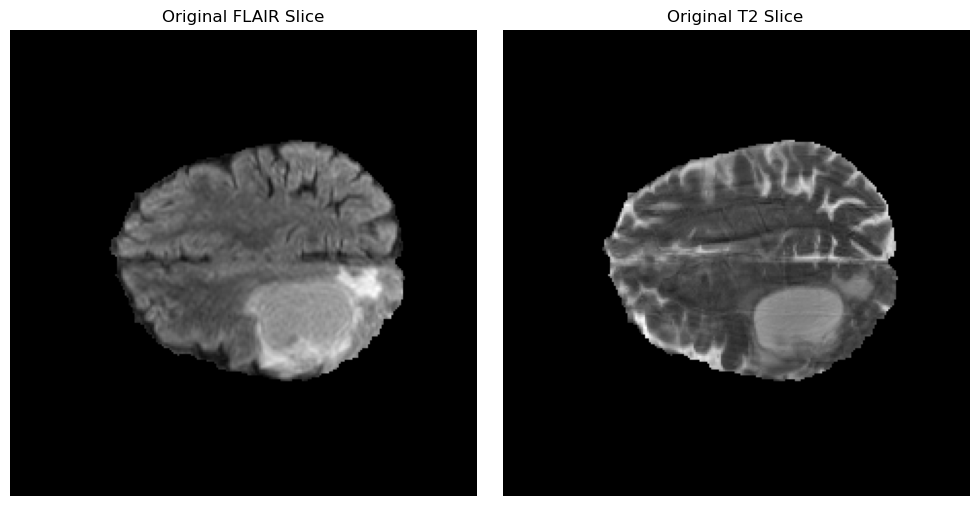

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Plot the FLAIR slice on the first subplot
axes[0].imshow(flair_slice_data.cpu().permute(1,2,0), cmap='gray')
axes[0].set_title('Original FLAIR Slice')
axes[0].axis('off')

# Plot the T2 slice on the second subplot
axes[1].imshow(t2_slice_data.cpu().permute(1,2,0), cmap='gray')
axes[1].set_title('Original T2 Slice')
axes[1].axis('off')

plt.tight_layout()
plt.show()

In [80]:
with torch.no_grad():
    flair_slice_tensor = flair_slice_data.unsqueeze(0).to(device)
    t2_slice_tensor = t2_slice_data.unsqueeze(0).to(device)
    
    recon_flair_test, _, _, _ = flair_model(flair_slice_tensor)
    quant_t_a, quant_b_a, _, _, _ = flair_model.encode(flair_slice_tensor)
    crossover_flair_to_t2_test = t2_model.decode(quant_t_a, quant_b_a)

    recon_t2_test, _, _, _ = t2_model(t2_slice_tensor)
    quant_t_b, quant_b_b, _, _, _ = t2_model.encode(t2_slice_tensor)
    crossover_t2_to_flair_test = flair_model.decode(quant_t_b, quant_b_b)

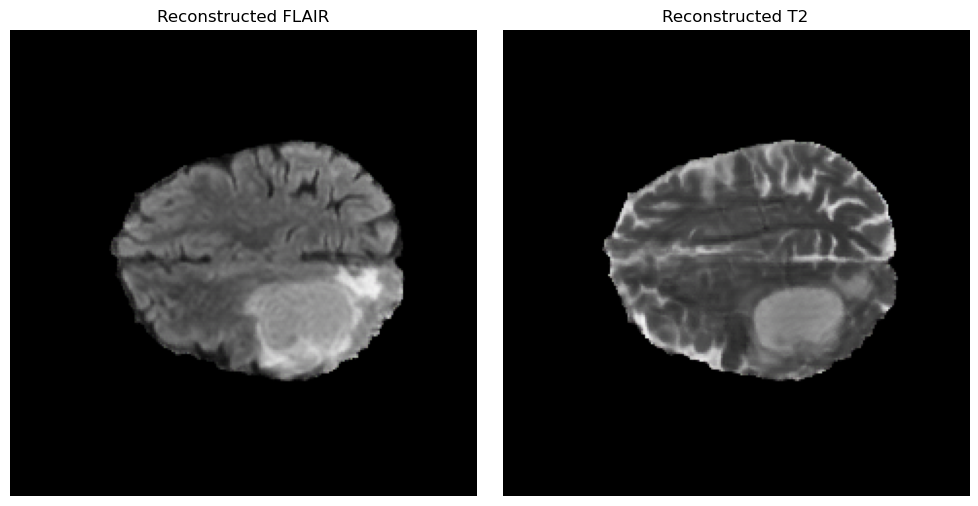

In [81]:
reconstructed_flair_to_plot = recon_flair_test.squeeze().permute(1, 2, 0).cpu().numpy()
reconstructed_t2_to_plot = recon_t2_test.squeeze().permute(1, 2, 0).cpu().numpy()

# --- Plot the images ---
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Plot the reconstructed FLAIR image
axes[0].imshow(reconstructed_flair_to_plot, cmap='gray')
axes[0].set_title("Reconstructed FLAIR")
axes[0].axis('off')

# Plot the reconstructed T2 image
axes[1].imshow(reconstructed_t2_to_plot, cmap='gray')
axes[1].set_title("Reconstructed T2")
axes[1].axis('off')

plt.tight_layout()
plt.show()

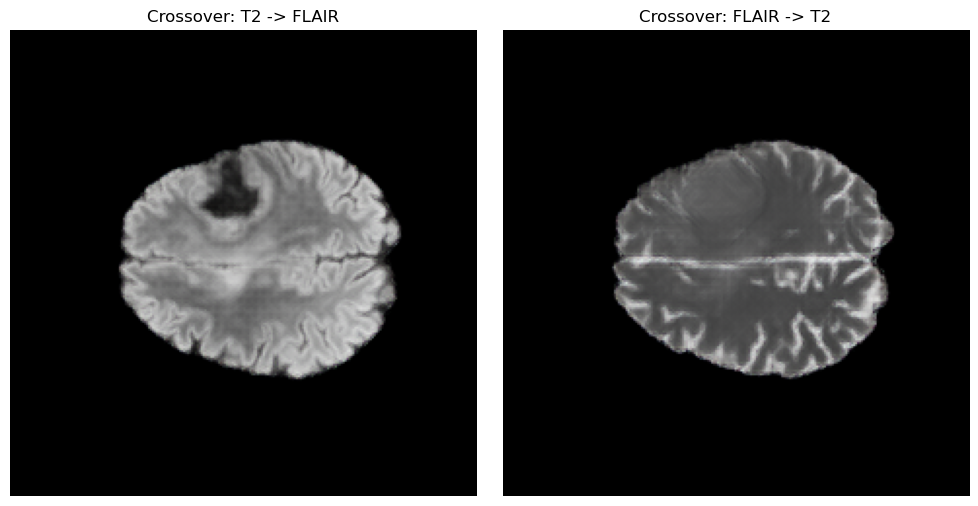

In [77]:
crossover_t2_to_flair_to_plot = crossover_t2_to_flair_test.squeeze().permute(1, 2, 0).cpu().numpy()
crossover_flair_to_t2_test_to_plot = crossover_flair_to_t2_test.squeeze().permute(1, 2, 0).cpu().numpy()

# --- Plot the images ---
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(crossover_t2_to_flair_to_plot, cmap='gray')
axes[0].set_title("Crossover: T2 -> FLAIR")
axes[0].axis('off')

axes[1].imshow(crossover_flair_to_t2_test_to_plot, cmap='gray')
axes[1].set_title("Crossover: FLAIR -> T2")
axes[1].axis('off')

plt.tight_layout()
plt.show()